In [14]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2

In [15]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)


In [16]:
# The model returns the original COCO ids (1-90), which skip some numbers.
# "N/A" fills those gaps so that COCO_CLASSES[class_id - 1] gives the right name.
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "N/A", "stop sign", "parking meter", "bench", "bird",
    "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "N/A",
    "backpack", "umbrella", "N/A", "N/A", "handbag", "tie", "suitcase", "frisbee", "skis",
    "snowboard", "sports ball", "kite", "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "N/A", "wine glass", "cup", "fork", "knife",
    "spoon", "bowl", "banana", "apple", "sandwich", "orange", "broccoli", "carrot", "hot dog",
    "pizza", "donut", "cake", "chair", "couch", "potted plant", "bed", "N/A", "dining table",
    "N/A", "N/A", "toilet", "N/A", "TV", "laptop", "mouse", "remote", "keyboard",
    "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "N/A", "book",
    "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush"
]

In [17]:
def detect_objects_with_boxes(image_path, detector):
    # Load and preprocess image
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")
    orig_image = image.copy()
    # OpenCV loads images as BGR, but the model expects RGB
    input_tensor = tf.convert_to_tensor(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run object detection
    detections = detector(input_tensor)

    # Extract detection results
    num_detections = int(detections["num_detections"].numpy()[0])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)
    detection_scores = detections["detection_scores"].numpy()[0]

    confidence_threshold = 0.5
    for i in range(num_detections):
        score = detection_scores[i]
        if score > confidence_threshold:
            # Get bounding box coordinates
            box = detection_boxes[i]
            h, w, _ = orig_image.shape
            y_min, x_min, y_max, x_max = box
            x_min, x_max = int(x_min * w), int(x_max * w)
            y_min, y_max = int(y_min * h), int(y_max * h)

            # Get object class name
            class_id = detection_classes[i]
            class_name = COCO_CLASSES[class_id - 1] if 1 <= class_id <= len(COCO_CLASSES) else "Unknown"

            # Draw bounding box and label
            label = f"{class_name}: {score:.2f}"
            cv2.rectangle(orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
            cv2.putText(
                orig_image,
                label,
                (x_min, y_min - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2,
            )

    return orig_image

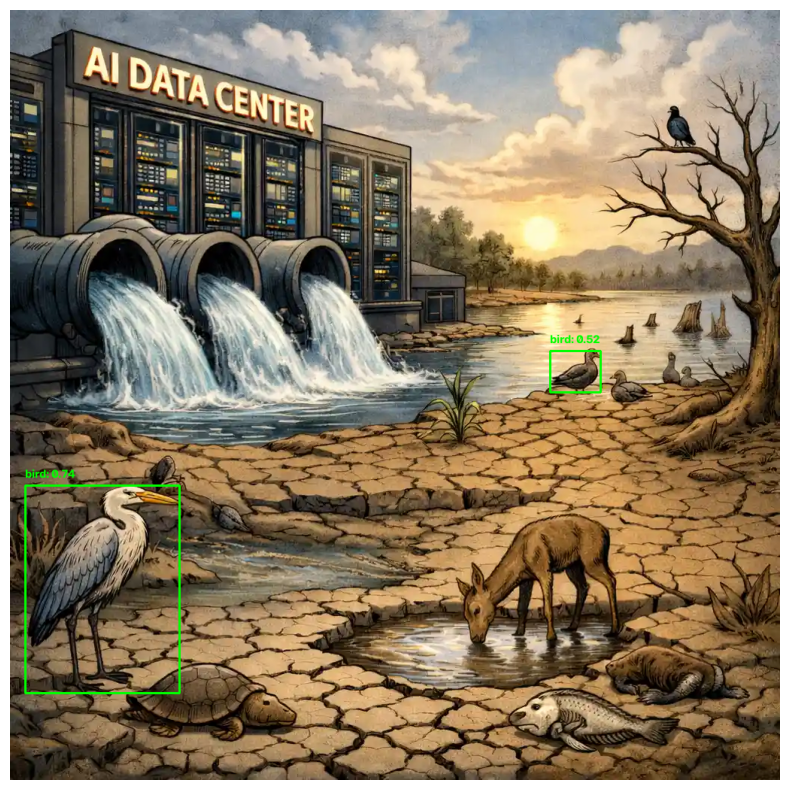

In [18]:
import os
import urllib.request
import matplotlib.pyplot as plt

image_path = "https://understandingyourai.org/ai-water-usage-myth/water.webp"  # Local file path or an http(s) image URL

# cv2.imread only reads local files, so download URLs first
if image_path.startswith(("http://", "https://")):
    local_path = os.path.basename(image_path)
    urllib.request.urlretrieve(image_path, local_path)
    image_path = local_path

# Detect objects and draw bounding boxes
result_image = detect_objects_with_boxes(image_path, detector)

# Display the result (cv2.imshow freezes the Jupyter kernel, so use matplotlib)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()